# 05. 평가 편향 점검과 시간순 재평가

기존 1.0은 조기 종료·모델 선택·임계값 선택에 사용한 Validation 성능으로 구분한다. 기존 Train 내부의 앞 80% 거래에 가까운 step 경계를 선택해 학습 구간과 내부 튜닝 구간을 분리한다. 세 후보의 모델과 임계값을 내부 튜닝 구간에서 결정한 뒤 저장하고, 기존 Validation을 읽어 고정 평가한다. 기존 Validation은 과거 특징 설계 과정에서 이미 관찰했으므로 완전히 새로운 독립 데이터로 간주하지 않는다. Test는 읽지 않고 최종 평가용으로 보존한다.

In [1]:
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
source_path = ROOT / "artifacts/features/paysim_temporal/20261117T090124Z-c769f595/manifest.json"
source = json.loads(source_path.read_text())
assert source["verified"]
base_features = source["model_features"]
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
report = ROOT / "artifacts/reports" / run_id
models = ROOT / "artifacts/models" / run_id
report.mkdir(parents=True)
models.mkdir(parents=True)
data_path = ROOT / source["parquet_path"]


def load_split(split):
    frame = pd.read_parquet(data_path / f"split={split}", columns=base_features + ["isFraud"])
    expected = next(item for item in source["splits"] if item["split"] == split)
    assert len(frame) == expected["rows"]
    assert int(frame.isFraud.sum()) == expected["fraud"]
    assert frame.step.min() == expected["min_step"] and frame.step.max() == expected["max_step"]
    return frame


def enrich(frame):
    frame["amount_to_origin_balance"] = frame.amount / (frame.oldbalanceOrg + 1.0)
    frame["origin_balance_minus_amount"] = frame.oldbalanceOrg - frame.amount
    frame["origin_balance_equals_amount"] = (frame.oldbalanceOrg == frame.amount).astype("int8")
    frame["origin_balance_zero"] = (frame.oldbalanceOrg == 0).astype("int8")
    frame["destination_balance_zero"] = (frame.oldbalanceDest == 0).astype("int8")
    frame["amount_to_destination_balance"] = frame.amount / (frame.oldbalanceDest + 1.0)
    frame["amount_to_receive_history"] = frame.amount / (frame.receive_prior_amount_mean + 1.0)
    return frame


train = load_split("train")
counts = train.groupby("step").size().sort_index()
# 정답을 사용하지 않고 누적 건수 80%에 가까운 step 경계를 선택한다.
boundary = int((counts.cumsum().iloc[:-1] - len(train) * 0.8).abs().idxmin())
fit = train.loc[train.step <= boundary].copy()
tune = train.loc[train.step > boundary].copy()
del train
categories = sorted(fit["type"].unique().tolist())
for frame in [fit, tune]:
    frame["type"] = pd.Categorical(frame["type"], categories=categories)
    enrich(frame)
assert fit.step.max() < tune.step.min()
assert fit.isFraud.nunique() == tune.isFraud.nunique() == 2
split_summary = [
    {
        "split": name,
        "rows": len(frame),
        "fraud": int(frame.isFraud.sum()),
        "min_step": int(frame.step.min()),
        "max_step": int(frame.step.max()),
    }
    for name, frame in [("inner_train", fit), ("inner_tune", tune)]
]
display(pd.DataFrame(split_summary))

,split,rows,fraud,min_step,max_step
0,inner_train,3066415,2649,1,234
1,inner_tune,754184,544,235,281


## 내부 튜닝과 모델 고정

기준 특징·잔액 특징 추가·송금자 잔액 전체 제거의 세 후보를 같은 설정으로 비교한다. 내부 튜닝 F1로 후보를 선택하고 모델을 재학습하지 않는다. 원본 잔액과 로그 잔액까지 제거하는 실험으로 전액 거래 패턴의 의존도를 평가한다.

In [2]:
def choose_threshold(labels, scores):
    p, r, thresholds = precision_recall_curve(labels, scores)
    denominator = p[:-1] + r[:-1]
    values = np.divide(
        2 * p[:-1] * r[:-1], denominator, out=np.zeros_like(thresholds), where=denominator > 0
    )
    return float(thresholds[np.flatnonzero(values == values.max())[-1]])


def metrics(labels, scores, threshold):
    assert len(labels) == len(scores) and np.isfinite(scores).all()
    prediction = scores >= threshold
    p, r, _ = precision_recall_curve(labels, scores)
    tn, fp, fn, tp = confusion_matrix(labels, prediction, labels=[0, 1]).ravel()
    return dict(
        threshold=threshold,
        precision=float(precision_score(labels, prediction, zero_division=0)),
        recall=float(recall_score(labels, prediction, zero_division=0)),
        f1=float(f1_score(labels, prediction, zero_division=0)),
        pr_auc=float(auc(r, p)),
        average_precision=float(average_precision_score(labels, scores)),
        tn=int(tn),
        fp=int(fp),
        fn=int(fn),
        tp=int(tp),
    )


full = [c for c in fit.columns if c != "isFraud"]
# 전액 거래 여부를 다른 특징으로 복원하지 못하도록 송금자 잔액과 파생 특징을 함께 제거한다.
removed = {
    "oldbalanceOrg",
    "oldbalanceOrg_log1p",
    "amount_to_origin_balance",
    "origin_balance_minus_amount",
    "origin_balance_equals_amount",
    "origin_balance_zero",
}
feature_sets = {
    "baseline": base_features,
    "balance_features": full,
    "without_origin_balance": [c for c in full if c not in removed],
}
for columns in feature_sets.values():
    assert not set(columns) & {
        "isFraud",
        "isFlaggedFraud",
        "newbalanceOrig",
        "newbalanceDest",
        "nameOrig",
        "nameDest",
    }
tune_results = []
candidate_specs = {}
for name, columns in feature_sets.items():
    model = lgb.LGBMClassifier(
        objective="binary",
        metric="average_precision",
        n_estimators=800,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=100,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=4,
        verbosity=-1,
        deterministic=True,
        force_col_wise=True,
    )
    model.fit(
        fit[columns],
        fit.isFraud,
        eval_set=[(tune[columns], tune.isFraud)],
        callbacks=[lgb.early_stopping(60), lgb.log_evaluation(100)],
    )
    scores = model.predict_proba(tune[columns])[:, 1]
    threshold = choose_threshold(tune.isFraud, scores)
    row = dict(name=name, **metrics(tune.isFraud, scores, threshold))
    tune_results.append(row)
    model_path = models / f"{name}.txt"
    model.booster_.save_model(str(model_path))
    candidate_specs[name] = dict(
        features=columns,
        threshold=threshold,
        best_iteration=model.best_iteration_,
        parameters=model.get_params(),
        sha256=hashlib.sha256(model_path.read_bytes()).hexdigest(),
    )
    print(row, flush=True)
# Validation을 읽기 전에 모델·임계값·선택 기준을 고정하고 기록한다.
selected = max(tune_results, key=lambda row: row["f1"])["name"]
frozen = dict(
    run_id=run_id,
    source_manifest=str(source_path.relative_to(ROOT)),
    boundary=boundary,
    splits=split_summary,
    categories=categories,
    selected=selected,
    candidates=candidate_specs,
    inner_tune_metrics=tune_results,
    frozen_at_utc=datetime.now(timezone.utc).isoformat(),
    test_evaluated=False,
    policy="Inner tune maximum F1; earlier candidate wins ties; no refit",
)
(models / "frozen_selection.json").write_text(json.dumps(frozen, indent=2))
display(pd.DataFrame(tune_results))
del fit, tune

/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 60 rounds


[100]	valid_0's average_precision: 0.741699


[200]	valid_0's average_precision: 0.7556


Early stopping, best iteration is:
[217]	valid_0's average_precision: 0.757011


{'name': 'baseline', 'threshold': 0.276877194573921, 'precision': 0.8367816091954023, 'recall': 0.6691176470588235, 'f1': 0.7436159346271706, 'pr_auc': 0.7571050644224918, 'average_precision': 0.7570111684417473, 'tn': 753569, 'fp': 71, 'fn': 180, 'tp': 364}


... (7 outputs left out)

[200]	valid_0's average_precision: 0.289396


Early stopping, best iteration is:
[149]	valid_0's average_precision: 0.302975


{'name': 'without_origin_balance', 'threshold': 0.08335732720401558, 'precision': 0.5139318885448917, 'recall': 0.30514705882352944, 'f1': 0.3829296424452134, 'pr_auc': 0.33391752397883995, 'average_precision': 0.30297510856032756, 'tn': 753483, 'fp': 157, 'fn': 378, 'tp': 166}


,name,threshold,precision,recall,f1,pr_auc,average_precision,tn,fp,fn,tp
0,baseline,0.276877,0.836782,0.669118,0.743616,0.757105,0.757011,753569,71,180,364
1,balance_features,0.006350,1.000000,1.000000,1.000000,1.000000,1.000000,753640,0,0,544
2,without_origin_balance,0.083357,0.513932,0.305147,0.382930,0.333918,0.302975,753483,157,378,166


## 기존 Validation에 고정 설정 적용

선택된 모델을 Validation 결과에 따라 변경하지 않는다. 후보별 수치는 의존도 진단을 위해 함께 기록한다. 검증 점수로 임계값을 재선택하지 않는다.

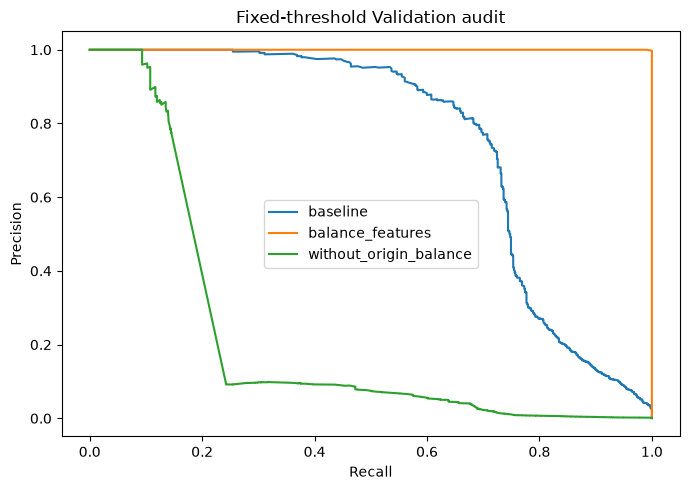

,name,threshold,precision,recall,f1,pr_auc,average_precision,tn,fp,fn,tp
0,baseline,0.276877,0.840678,0.650919,0.733728,0.750220,0.750157,1247642,94,266,496
1,balance_features,0.006350,0.997382,1.000000,0.998689,0.999988,0.999976,1247734,2,0,762
2,without_origin_balance,0.083357,0.091720,0.242782,0.133141,0.217967,0.184786,1245904,1832,577,185


Run: 20261119T073653Z-1d0e70df Selected using inner tune: balance_features


In [3]:
# 저장된 모델과 임계값으로만 기존 Validation을 평가한다.
frozen = json.loads((models / "frozen_selection.json").read_text())
valid = load_split("validation")
assert frozen["splits"][1]["max_step"] < valid.step.min()
valid["type"] = pd.Categorical(valid["type"], categories=frozen["categories"])
enrich(valid)
rows = []
fig, ax = plt.subplots(figsize=(7, 5))
for name, spec in frozen["candidates"].items():
    model_path = models / f"{name}.txt"
    assert hashlib.sha256(model_path.read_bytes()).hexdigest() == spec["sha256"]
    booster = lgb.Booster(model_file=str(model_path))
    scores = booster.predict(valid[spec["features"]])
    row = dict(name=name, **metrics(valid.isFraud, scores, spec["threshold"]))
    rows.append(row)
    p, r, _ = precision_recall_curve(valid.isFraud, scores)
    ax.plot(r, p, label=name)
    if name == frozen["selected"]:
        pd.DataFrame({"label": valid.isFraud, "score": scores}).to_parquet(
            report / "validation_predictions.parquet", index=False
        )
ax.set(xlabel="Recall", ylabel="Precision", title="Fixed-threshold Validation audit")
ax.legend()
fig.tight_layout()
fig.savefig(report / "audit_pr_curves.png", dpi=150)
plt.show()
table = pd.DataFrame(rows)
display(table)
table.to_csv(report / "validation_audit.csv", index=False)
manifest = dict(
    **frozen,
    validation_metrics=rows,
    validation_used_for_current_selection=False,
    validation_previously_seen=True,
    limitation="Historical Validation informed previous feature design; Test remains unused",
    versions={"lightgbm": lgb.__version__, "pandas": pd.__version__},
)
(report / "manifest.json").write_text(json.dumps(manifest, indent=2))
(models / "manifest.json").write_text(json.dumps(manifest, indent=2))
print("Run:", run_id, "Selected using inner tune:", frozen["selected"])